# Phase 3 — Is the relationship stable? Rolling β + rolling ADF (in-sample only)

**In-sample only: dates < 2013-01-01.** No Phase 2 parameter is changed and no new backtest is run (IS backtest counter stays at 11).

Design pre-registered in `EXPERIMENTS.md` (2026-10-10 13:20 CEST) before computing — the brief's "medium" method, on log prices:

- **Rolling β**: OLS slope of log P_INTC on log P_AMD over the last W = 252 days (one year), for every day.
- **Rolling ADF**: every 21 trading days, the spread of the window built with the window's own β, ADF test (constant, AIC lags).
- **Weak period**: ADF p-value > 0.05. The p-value computed at the close of day t_k is used from day t_k + 1 (no look-ahead).
- **Check**: does the Phase 2 main configuration (e = 2.0, L = 60, static β) earn less on weak days?

Declared limitations: (1) the ADF p-value with a β estimated in the same window is optimistic → weak periods *under*-counted; (2) with 252 observations the ADF has low power → weak periods *over*-counted; (3) windows overlap by ~92%, so flags are persistent and the Welch p-value is approximate; (4) the flag says whether a relationship with a *local* β exists in the period, not whether the *static-β* spread the strategy trades is stationary.

In [1]:
import logging

import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display

from pairs.backtest import run_strategy
from pairs.config import SPLIT_DATE
from pairs.data import load_pair
from pairs.metrics import performance_summary
from pairs.plotting import DERIVED_COLOR, apply_style, save_figure, shade_periods
from pairs.spread import compute_spread, fit_hedge_ratio
from pairs.stability import (
    DEFAULT_STEP,
    DEFAULT_WINDOW,
    WEAK_PVALUE,
    regime_comparison,
    rolling_adf,
    rolling_beta,
    weak_flag,
)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("kaleido", "choreographer"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

# Pre-registered (EXPERIMENTS.md 2026-10-10 13:20 CEST). Do not edit.
assert (DEFAULT_WINDOW, DEFAULT_STEP, WEAK_PVALUE) == (252, 21, 0.05)
MAIN_ENTRY, MAIN_LOOKBACK, COST_BPS = 2.0, 60, 5.0

In [2]:
prices = load_pair(end=SPLIT_DATE)
assert prices.index.max() < pd.Timestamp(SPLIT_DATE)

fit = fit_hedge_ratio(prices, end=SPLIT_DATE)
assert round(fit.beta, 4) == 1.0471, "static beta must match Phase 2"

beta_roll = rolling_beta(prices, end=SPLIT_DATE)
adf = rolling_adf(prices, end=SPLIT_DATE)
flag = weak_flag(adf, pd.DatetimeIndex(prices.index))

print(
    f"{len(adf)} rolling ADF windows, "
    f"first computed on {adf.index[0].date()}, last on {adf.index[-1].date()}"
)
print(f"First day with a flag: {flag.dropna().index[0].date()}")

INFO pairs.data: Loaded INTC/AMD: 8273 common days, 1980-03-17 -> 2012-12-31 (end=2013-01-01, exclusive)


INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 1980-03-17..2012-12-31: alpha=-1.2311 beta=1.0471 R2=0.1499


INFO pairs.stability: Rolling ADF: 382 windows of 252 days every 21 days, 1981-03-16..2012-11-30


382 rolling ADF windows, first computed on 1981-03-16, last on 2012-11-30
First day with a flag: 1981-03-17


## 1. How much does β move over time?

Static β (whole IS) = 1.047. The rolling β is re-estimated every day on the last year only. If the relationship were stable, it would wander moderately around the static value.

INFO pairs.plotting: Saved figure 03a_rolling_beta_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


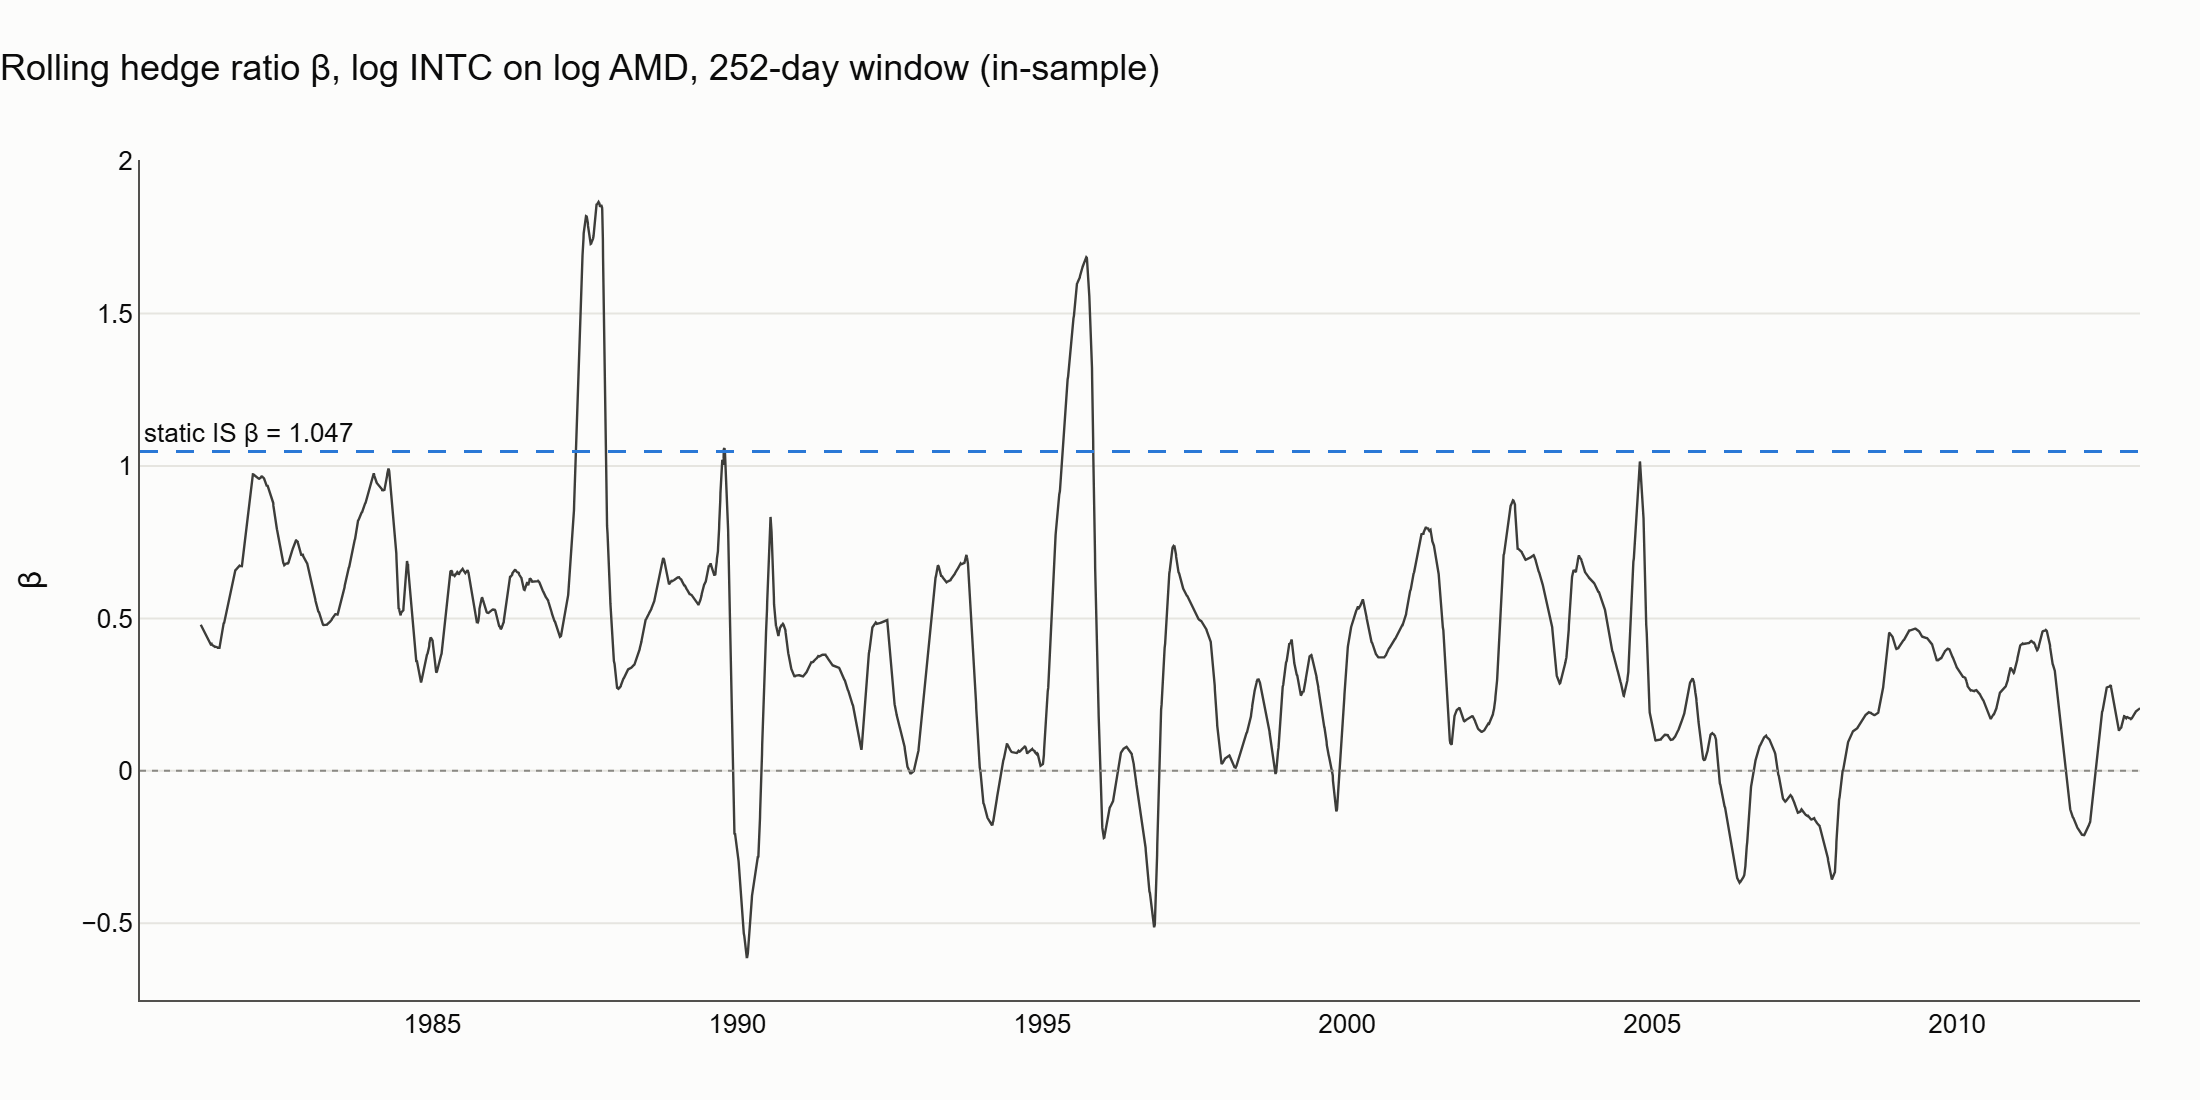

,value
min,-0.614
5th percentile,-0.177
median,0.386
95th percentile,0.953
max,1.865
std,0.371
% of days with β ≤ 0,12.241
% of days with β ≤ 0.1,20.531


In [3]:
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=beta_roll.index,
        y=beta_roll,
        name="rolling β (252 days)",
        line={"color": DERIVED_COLOR, "width": 1.2},
    )
)
fig.add_hline(
    y=fit.beta,
    line={"color": "#2a78d6", "width": 1.5, "dash": "dash"},
    annotation_text=f"static IS β = {fit.beta:.3f}",
    annotation_position="top left",
)
fig.add_hline(y=0, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "Rolling hedge ratio β, log INTC on log AMD, 252-day window (in-sample)")
fig.update_layout(showlegend=False)
fig.update_yaxes(title_text="β")
_, png = save_figure(fig, "03a_rolling_beta_is")
display(Image(filename=png))

b = beta_roll.dropna()
pd.DataFrame(
    {
        "value": [
            b.min(),
            b.quantile(0.05),
            b.median(),
            b.quantile(0.95),
            b.max(),
            b.std(),
            100 * (b <= 0).mean(),
            100 * (b <= 0.1).mean(),
        ]
    },
    index=[
        "min",
        "5th percentile",
        "median",
        "95th percentile",
        "max",
        "std",
        "% of days with β ≤ 0",
        "% of days with β ≤ 0.1",
    ],
).round(3)

## 2. Rolling ADF p-value and weak periods

Dots: p-value of each window, plotted on the day it is computed. Shaded: days flagged weak (p > 0.05), which start the day *after* the computation.

INFO pairs.plotting: Saved figure 03b_rolling_adf_pvalue_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


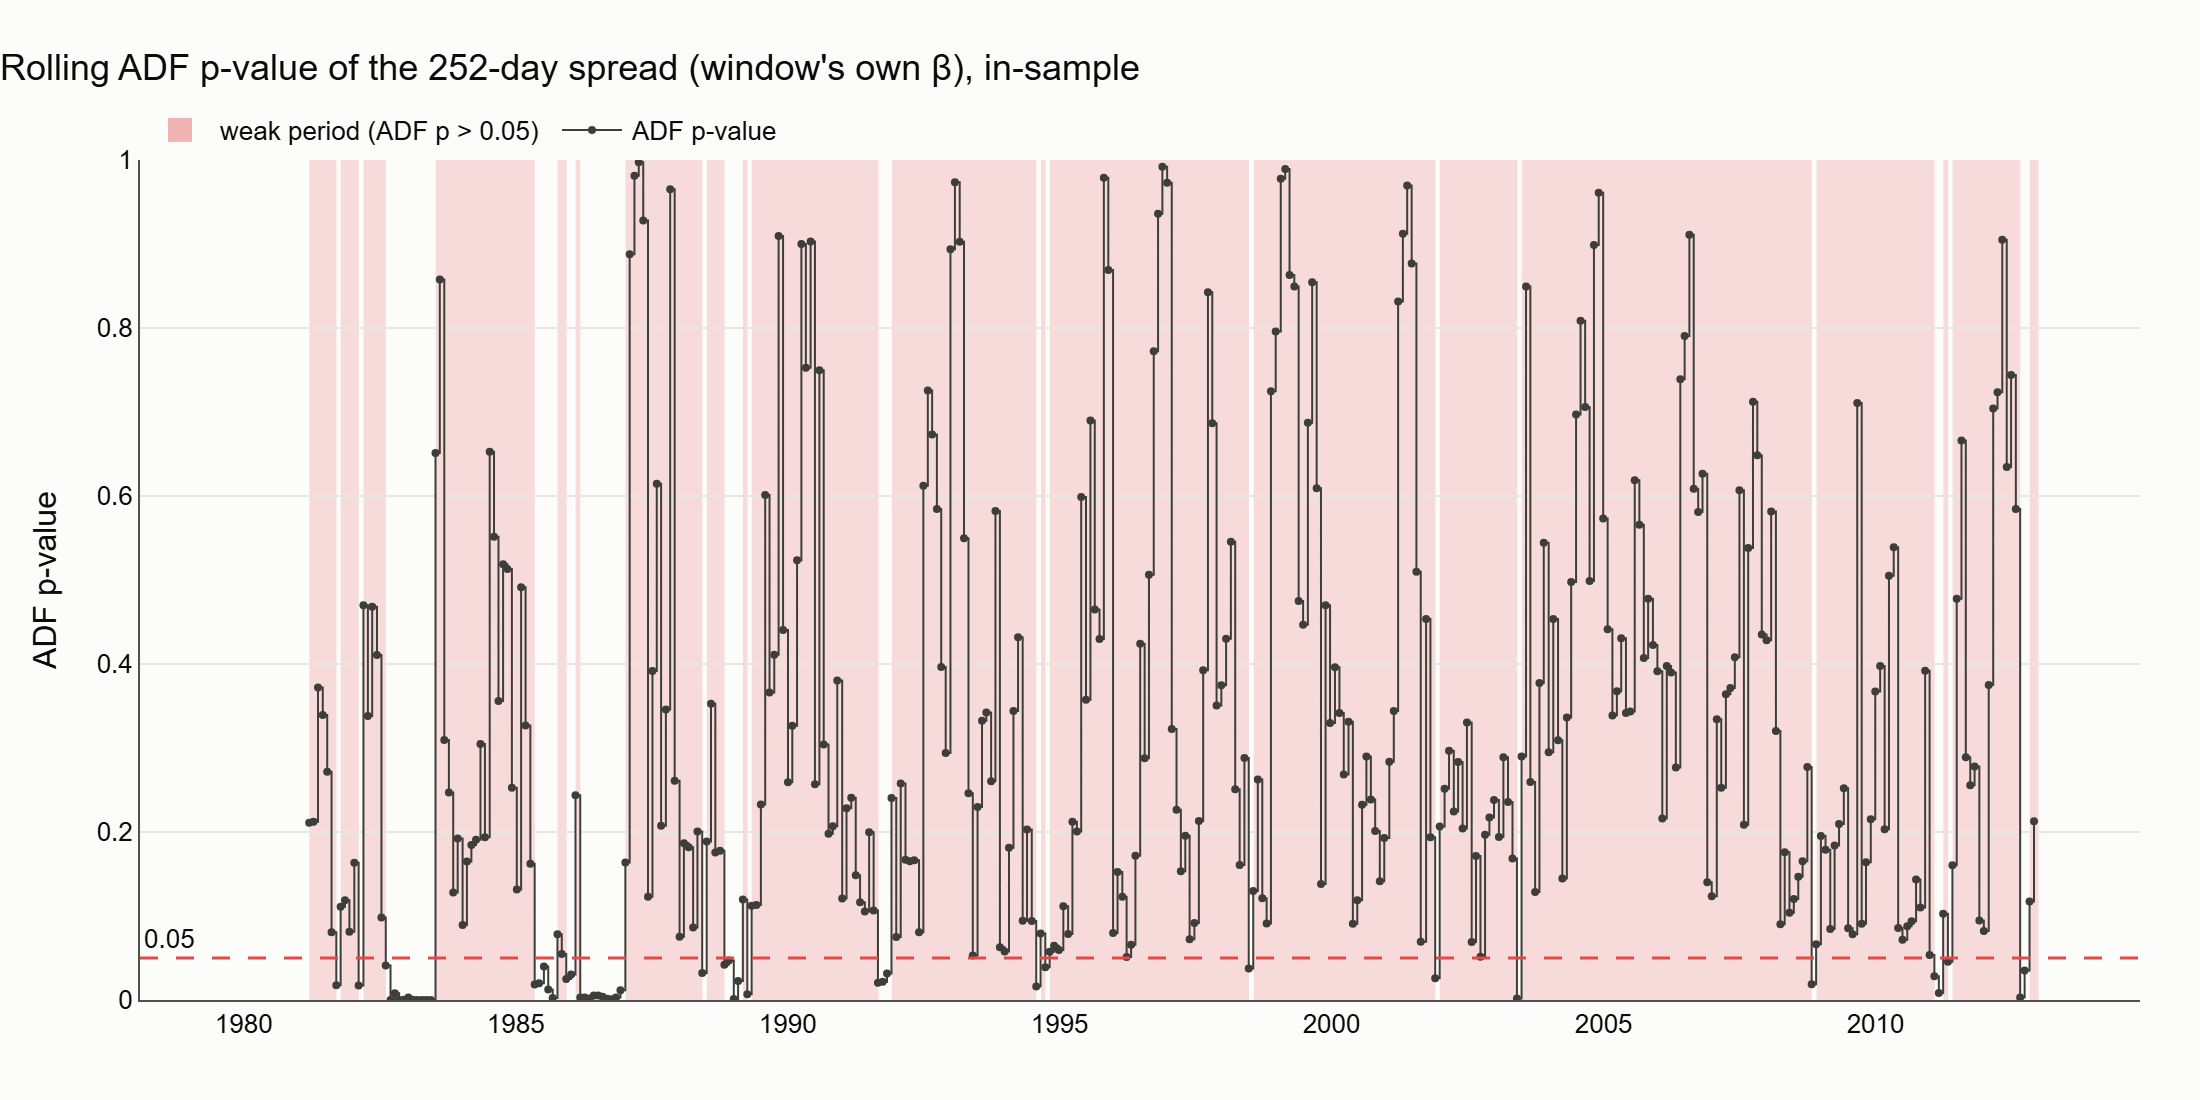

Weak share of all flagged IS days (1981-03-17 -> 2012-12-31): 86.9% (6971 of 8021 days); windows with p > 0.05: 332 of 382.


In [4]:
fig = go.Figure()
shade_periods(fig, flag, label="weak period (ADF p > 0.05)")
fig.add_trace(
    go.Scatter(
        x=adf.index,
        y=adf["adf_pvalue"],
        name="ADF p-value",
        mode="lines+markers",
        line={"color": DERIVED_COLOR, "width": 1, "shape": "hv"},
        marker={"size": 4},
    )
)
fig.add_hline(
    y=WEAK_PVALUE,
    line={"color": "#e34948", "width": 1.5, "dash": "dash"},
    annotation_text="0.05",
    annotation_position="top left",
)
apply_style(fig, "Rolling ADF p-value of the 252-day spread (window's own β), in-sample")
fig.update_yaxes(title_text="ADF p-value", range=[0, 1])
_, png = save_figure(fig, "03b_rolling_adf_pvalue_is")
display(Image(filename=png))

flagged = flag.dropna()
print(
    f"Weak share of all flagged IS days ({flagged.index[0].date()} -> {flagged.index[-1].date()}): "
    f"{100 * flagged.astype(bool).mean():.1f}% "
    f"({int(flagged.astype(bool).sum())} of {len(flagged)} days); "
    f"windows with p > 0.05: {int((adf['adf_pvalue'] > WEAK_PVALUE).sum())} of {len(adf)}."
)

## 3. Does the Phase 2 signal do worse in weak periods?

Main configuration (e = 2.0, L = 60, static β, lag 1, 5 bp/leg) on the Phase 2 evaluation window, recomputed with the same function and parameters: identical by construction to Phase 2 (asserted below), **not a new backtest**.

INFO pairs.backtest: log e=2.0 L=60 lag=1: 115 trades, 1980-09-04..2012-12-31


INFO pairs.plotting: Saved figure 03c_equity_weak_shaded_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


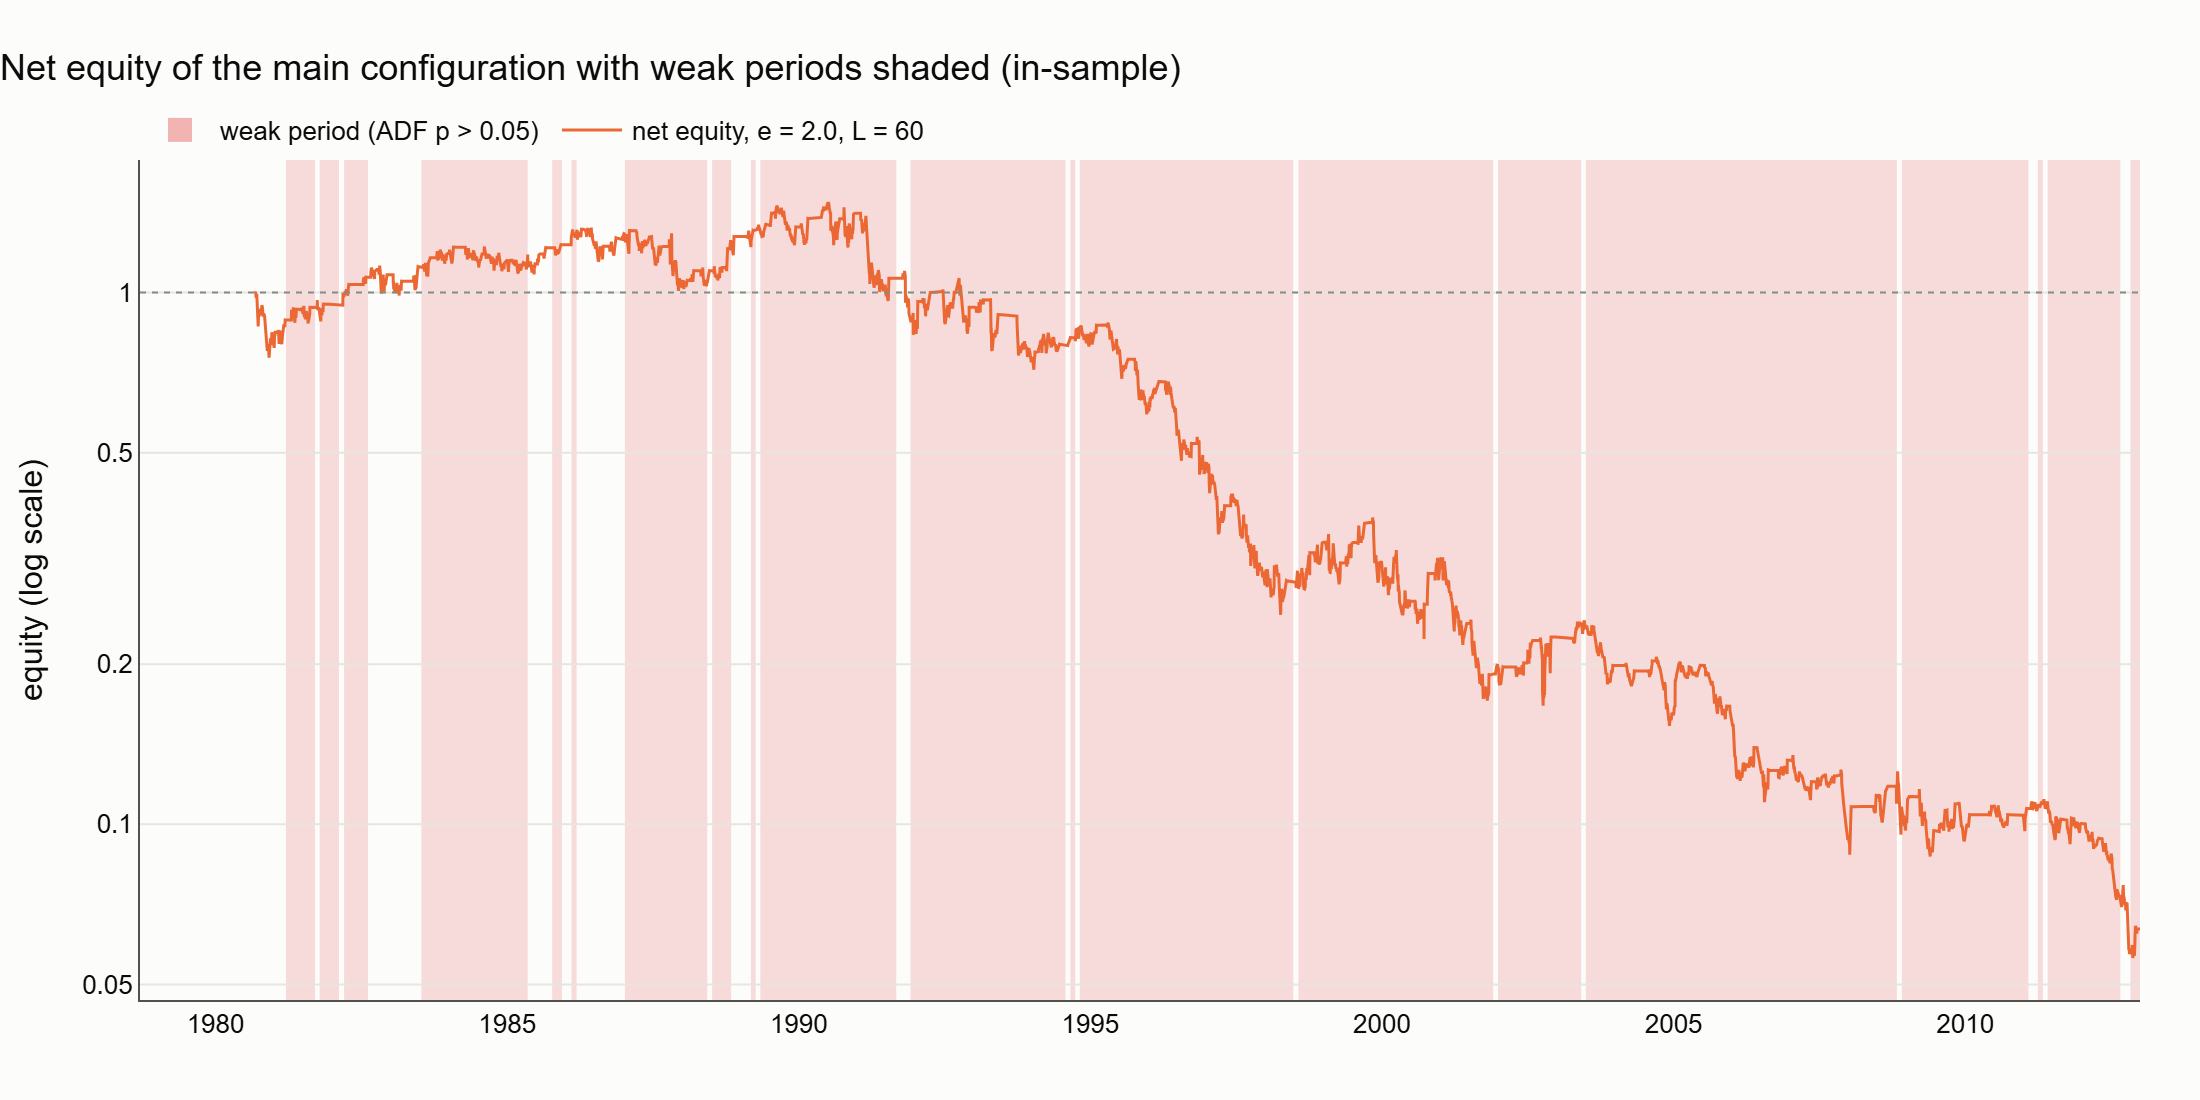

In [5]:
spread = compute_spread(prices, fit.beta)
trade_from = spread.index[120 - 1].date()  # Phase 2 common evaluation window
run = run_strategy(
    prices,
    fit.beta,
    entry=MAIN_ENTRY,
    lookback=MAIN_LOOKBACK,
    end=SPLIT_DATE,
    trade_from=trade_from,
    lag=1,
    cost_bps=COST_BPS,
)
summary = performance_summary(run.daily, run.trades)
assert round(summary["sharpe_net"], 2) == -0.27 and int(summary["n_trades"]) == 115, (
    "must match Phase 2"
)

equity = (1 + run.daily["net_ret"]).cumprod()
fig = go.Figure()
shade_periods(fig, flag.reindex(run.daily.index), label="weak period (ADF p > 0.05)")
fig.add_trace(
    go.Scatter(
        x=equity.index,
        y=equity,
        name="net equity, e = 2.0, L = 60",
        line={"color": "#eb6834", "width": 1.5},
    )
)
fig.add_hline(y=1, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "Net equity of the main configuration with weak periods shaded (in-sample)")
fig.update_yaxes(type="log", tickvals=[0.05, 0.1, 0.2, 0.5, 1, 2], title_text="equity (log scale)")
_, png = save_figure(fig, "03c_equity_weak_shaded_is")
display(Image(filename=png))

In [6]:
cmp = regime_comparison(run.daily, run.trades, flag)
table = cmp.table.copy()
for col in ["share_days", "exposure", "ann_return", "max_dd", "win_rate_net"]:
    table[col] = 100 * table[col]
table["mean_daily_net"] = 1e4 * table["mean_daily_net"]
table = table.rename(
    columns={
        "share_days": "share_days %",
        "exposure": "exposure %",
        "mean_daily_net": "mean_daily_net bp",
        "ann_return": "ann_return %",
        "max_dd": "max_dd %",
        "win_rate_net": "win_rate_net %",
    }
).astype({"n_days": int, "n_trades": int})
display(table.round(2))
print(
    "Welch t-test, mean daily net return weak − strong: "
    f"t = {cmp.welch_t:.2f}, p = {cmp.welch_pvalue:.3f} "
    "(approximate: returns are autocorrelated and regimes come in long blocks)."
)
print(
    "Excluded because no flag existed yet: "
    f"{cmp.n_days_unflagged} days, {cmp.n_trades_unflagged} trades."
)

,n_days,share_days %,exposure %,mean_daily_net bp,ann_return %,sharpe,max_dd %,n_trades,win_rate_net %
weak,6971,86.91,64.73,-2.40,-8.21,-0.27,-94.22,90,50.00
strong,1050,13.09,55.71,-1.72,-6.23,-0.21,-38.74,23,69.57


Welch t-test, mean daily net return weak − strong: t = -0.16, p = 0.875 (approximate: returns are autocorrelated and regimes come in long blocks).
Excluded because no flag existed yet: 133 days, 2 trades.


In [7]:
# Where are the strong (ADF p <= 0.05) days? Share of flagged days per decade (descriptive).
f = flag.dropna().astype(bool)
by_decade = (
    pd.DataFrame({"weak": f, "decade": (f.index.year // 10) * 10})
    .groupby("decade")["weak"]
    .agg(flagged_days="size", strong_pct=lambda w: 100 * (~w).mean())
)
by_decade.index = [f"{d}s" for d in by_decade.index]
by_decade.round(1)

,flagged_days,strong_pct
1980s,2224,34.0
1990s,2528,5.0
2000s,2515,2.5
2010s,754,13.9


## Observations (in-sample only; nothing in Phase 2 was changed)

- **β is far from stable.** The one-year rolling β has median 0.39, 5th–95th percentile −0.18 to 0.95, extremes −0.61 and 1.87 (std 0.37). It is ≤ 0 on 12% of days and ≤ 0.1 on 21%: for about a fifth of the IS the AMD leg is locally no hedge at all. The static β = 1.047 used in Phase 2 lies **above the 95th percentile** of the rolling β: the whole-sample regression of log levels is driven by the long-run co-trend of the two prices, not by how they move together within a year.
- **Most of the IS is "weak".** 332 of 382 rolling windows have ADF p > 0.05, i.e. 86.9% of the flagged IS days (6,971 of 8,021). Strong days are concentrated in the 1980s (34% of that decade's days) and almost absent in the 1990s (5%) and 2000s (2.5%); 13.9% in 2010–2012. Part of this is the low power of a 252-day ADF (declared limitation 2), but the direction agrees with Phase 2: no stable relationship over most of the sample.
- **Does the signal do worse on weak days? Slightly, but not distinguishably.** Weak days: Sharpe −0.27, −8.2% a year, −2.4 bp/day, exposure 65%. Strong days: Sharpe −0.21, −6.2% a year, −1.7 bp/day, exposure 56%. Welch t = −0.16, p = 0.88: no evidence of a difference (and the p-value is approximate). The strategy **loses in both regimes**. Trades entered on strong days win more often (70% of 23 trades vs 50% of 90), but 23 trades are too few to rely on. The max drawdowns (−94% vs −39%) are not comparable, because the weak curve is stitched from almost seven times as many days.
- **Excluded:** 133 days and 2 trades before the first flag (1980-09-04 to 1981-03-16).
- **Reading.** The flag does not rescue the strategy: even where a local relationship exists, the Phase 2 signal trades the *static*-β spread, whose β (1.047) is far from the local one (median 0.39) — declared limitation 4 in action. A hypothesis, **not tested here**: with a local β around 0.4 and a hedge of 1.05 units of AMD, the static-β spread behaves largely like a position in AMD itself, which would explain why it follows AMD's large cycles.